# Time Series Classification Explanations on UCR FordA with TS-MULE

This notebook demonstrates how to use `tsmule` to explain a black-box time series classifier on the **FordA** dataset (univariate engine noise classification, 500 time steps per sample) across **all 7 TS-MULE segmentation strategies**, visualize the resulting attributions side by side, and evaluate faithfulness using `PerturbationAnalysis`.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.metrics import accuracy_score, brier_score_loss

if os.path.exists('ford_a_classification.py') and os.path.abspath('../..') not in sys.path:
    sys.path.insert(0, os.path.abspath('../..'))

from examples.ford_a.ford_a_classification import (
    FORDA_METHODS,
    build_segmenter,
    load_forda,
    plot_methods_relevance,
    plot_perturbation_comparison,
    train_forda_classifier,
)
from tsmule.xai.evaluation import PerturbationAnalysis
from tsmule.xai.lime import LimeTS

## 1. Load FordA and Train a Classifier

In [2]:
X_train, y_train, X_test, y_test = load_forda()
print(f'Train: {X_train.shape}, Test: {X_test.shape}')

model = train_forda_classifier(X_train, y_train, seed=42)
print(f'Test Accuracy: {accuracy_score(y_test, model.predict(X_test)):.4f}')

Train: (3601, 500), Test: (1320, 500)


Test Accuracy: 0.8409


## 2. Explain a Classification Prediction Across All 7 TS-MULE Methods

When `predict_fn` returns class probabilities (`model.predict_proba`), `LimeTS.explain(..., batch_predict=True)` automatically selects `target_class = argmax(predict_proba(x))` (or you can pass `target_class=0` / `target_class=1` explicitly). Here we compare all 7 segmentation strategies using smaller windows (`partitions=50`, `win_length=10`).

uniform           | segments=50 | R2=0.724


exponential       | segments= 7 | R2=0.713


slopes-sorted     | segments=51 | R2=0.700


slopes-not-sorted | segments=50 | R2=0.778


bins-min          | segments= 9 | R2=0.925


bins-max          | segments=26 | R2=0.826


sax               | segments=125 | R2=0.067


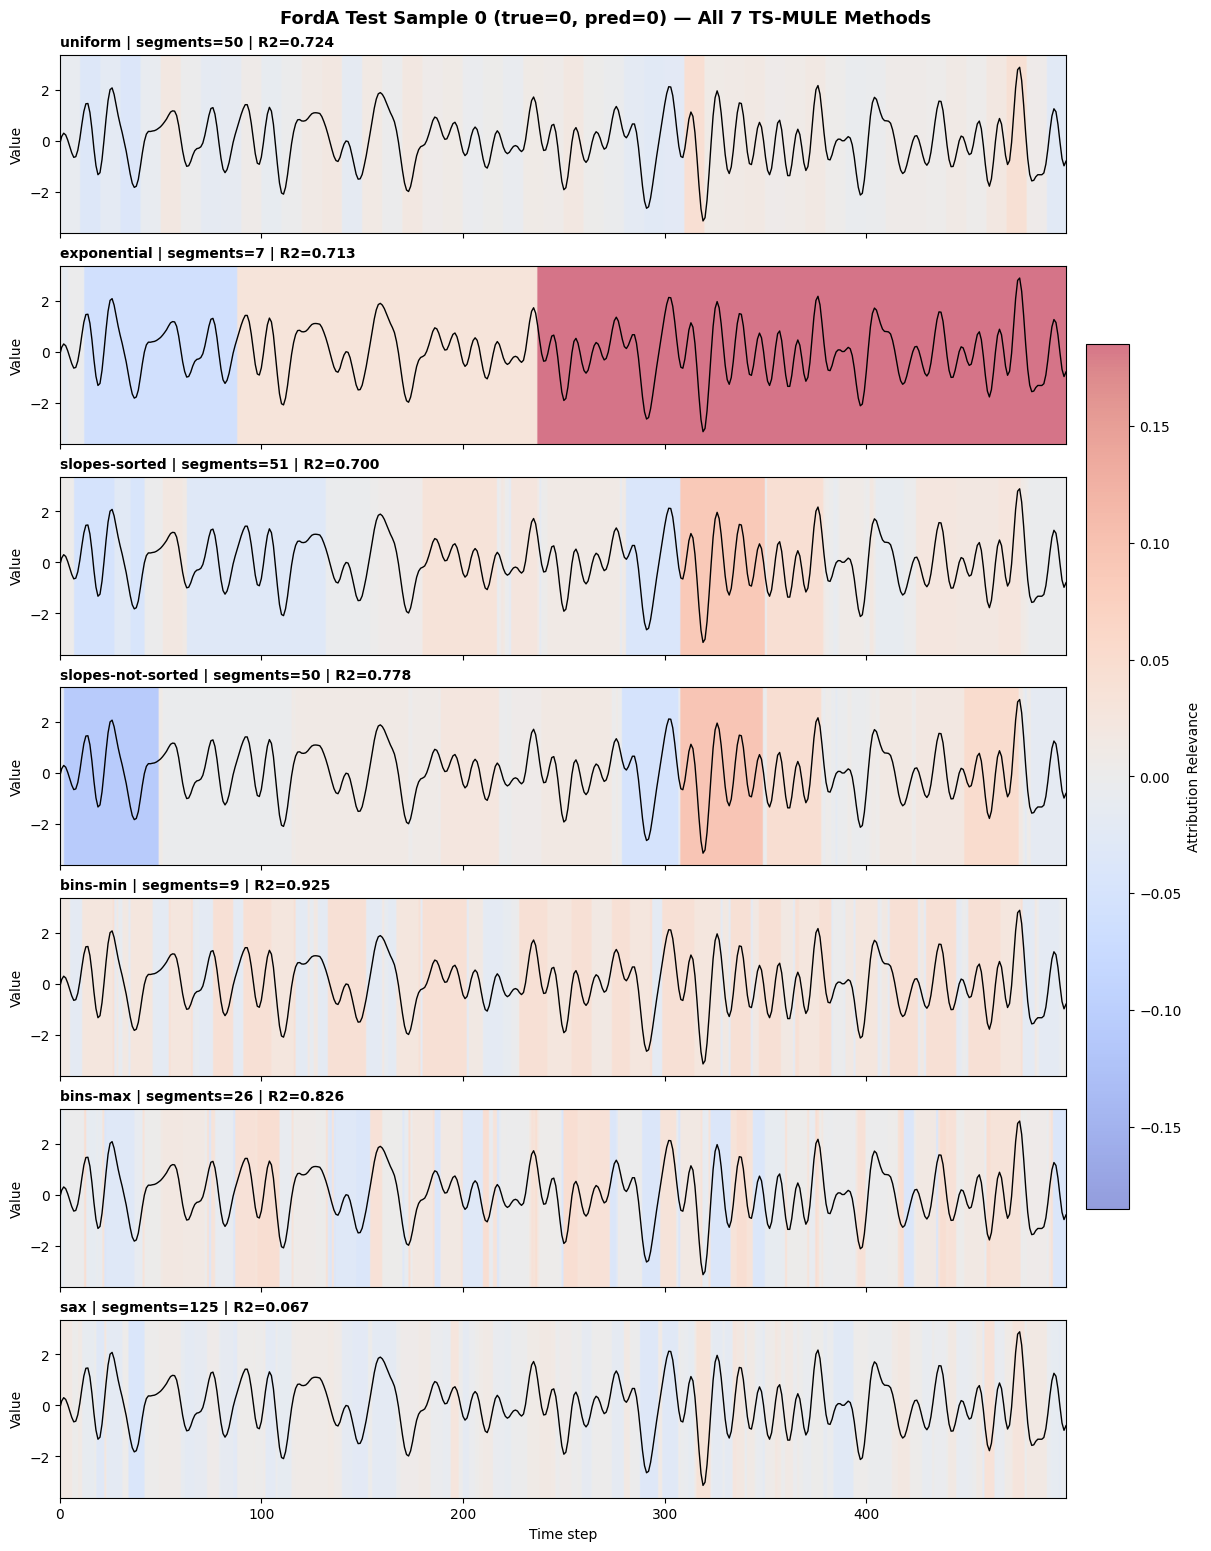

In [3]:
sample = X_test[0]
sample_relevances = {}
sample_r2 = {}
sample_seg_counts = {}
explained_class = None

for method in FORDA_METHODS:
    segmenter, seg_method = build_segmenter(method, partitions=50, win_length=10)
    seg_mask = (
        segmenter.segment(sample)
        if seg_method is None
        else segmenter.segment(sample, segmentation_method=seg_method)
    )
    sample_seg_counts[method] = int(len(np.unique(seg_mask)))

    explainer = LimeTS(
        kernel=Ridge(alpha=1.0),
        segmenter=segmenter,
        replace_method='zeros',
        n_samples=200,
        random_state=42,
    )
    rel = explainer.explain(
        sample,
        model.predict_proba,
        segmentation_method=seg_method,
        batch_predict=True,
    )
    explained_class = explainer.target_class
    sample_relevances[method] = rel
    sample_r2[method] = explainer.score
    print(f'{method:17s} | segments={sample_seg_counts[method]:2d} | R2={explainer.score:.3f}')

fig = plot_methods_relevance(
    sample,
    sample_relevances,
    r2_by_method=sample_r2,
    seg_counts=sample_seg_counts,
    title=f'FordA Test Sample 0 (true={y_test[0]}, pred={explained_class}) — All 7 TS-MULE Methods',
)
plt.show()

## 3. Evaluate All 7 Methods with `PerturbationAnalysis`

uniform           | R2=0.683 | acc(o/r/p)=0.950/0.900/0.725 (valid=True, score=4.50) | brier(o/r/p)=0.079/0.090/0.186 (valid=True, score=9.87)


exponential       | R2=0.647 | acc(o/r/p)=0.950/0.950/0.950 (valid=True, score=nan) | brier(o/r/p)=0.079/0.077/0.077 (valid=False, score=0.81)


slopes-sorted     | R2=0.641 | acc(o/r/p)=0.950/0.925/0.925 (valid=True, score=1.00) | brier(o/r/p)=0.079/0.081/0.093 (valid=True, score=7.82)


slopes-not-sorted | R2=0.640 | acc(o/r/p)=0.950/0.900/0.825 (valid=True, score=2.50) | brier(o/r/p)=0.079/0.090/0.139 (valid=True, score=5.54)


bins-min          | R2=0.866 | acc(o/r/p)=0.950/0.925/0.900 (valid=True, score=2.00) | brier(o/r/p)=0.079/0.082/0.093 (valid=True, score=4.27)


bins-max          | R2=0.820 | acc(o/r/p)=0.950/0.900/0.825 (valid=True, score=2.50) | brier(o/r/p)=0.079/0.084/0.125 (valid=True, score=10.05)


sax               | R2=0.525 | acc(o/r/p)=0.950/0.900/0.650 (valid=True, score=6.00) | brier(o/r/p)=0.079/0.087/0.203 (valid=True, score=15.89)


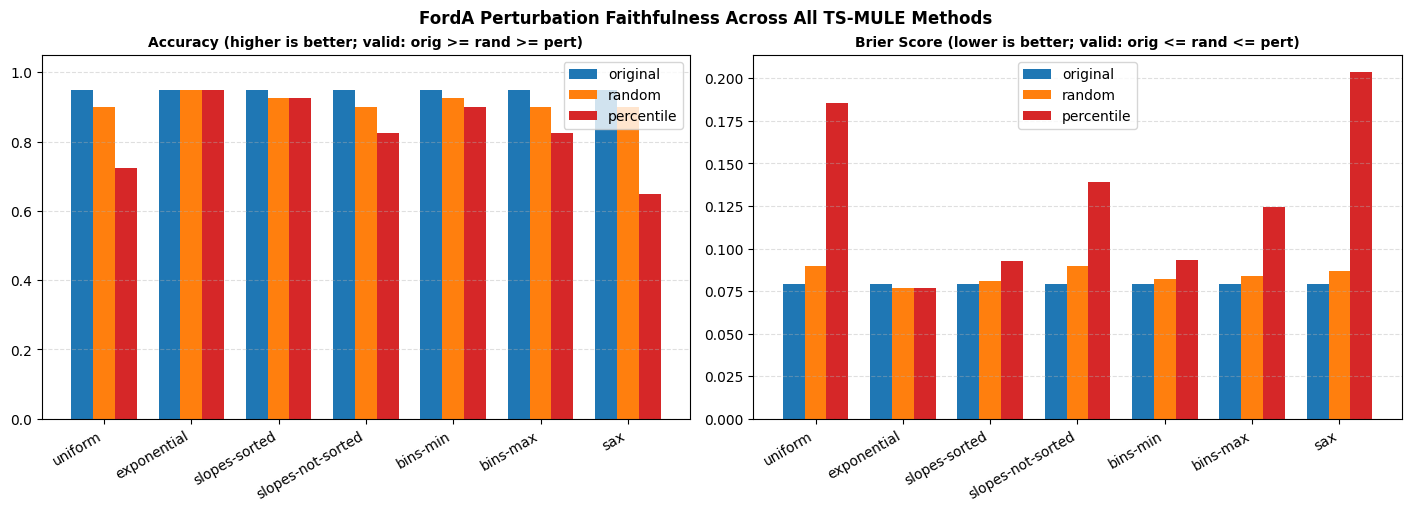

In [4]:
X_sub = X_test[:40]
y_sub = y_test[:40]
eval_results = {}

for method in FORDA_METHODS:
    segmenter, seg_method = build_segmenter(method, partitions=50, win_length=10)
    explainer = LimeTS(
        kernel=Ridge(alpha=1.0),
        segmenter=segmenter,
        replace_method='zeros',
        n_samples=200,
        random_state=42,
    )
    relevances = []
    r2_scores = []
    for x in X_sub:
        relevances.append(
            explainer.explain(
                x,
                model.predict_proba,
                segmentation_method=seg_method,
                batch_predict=True,
            )
        )
        r2_scores.append(explainer.score)
    relevances = np.asarray(relevances)

    pa_acc = PerturbationAnalysis()
    acc_ins = pa_acc.analysis_relevance(
        X_sub,
        y_sub,
        relevances,
        predict_fn=model.predict,
        eval_fn=accuracy_score,
        replace_method='zeros',
        percentile=80,
        use_abs=True,
        random_state=42,
    )

    pa_brier = PerturbationAnalysis()
    brier_ins = pa_brier.analysis_relevance(
        X_sub,
        y_sub,
        relevances,
        predict_fn=lambda batch: model.predict_proba(batch)[:, 1],
        eval_fn=brier_score_loss,
        replace_method='zeros',
        percentile=80,
        use_abs=True,
        random_state=42,
    )

    eval_results[method] = {
        'mean_r2': float(np.mean(r2_scores)),
        'acc': acc_ins,
        'acc_valid': pa_acc.is_valid(higher_is_better=True),
        'acc_score': pa_acc.perturbation_score(),
        'brier': brier_ins,
        'brier_valid': pa_brier.is_valid(higher_is_better=False),
        'brier_score': pa_brier.perturbation_score(),
    }
    print(
        f"{method:17s} | R2={eval_results[method]['mean_r2']:.3f} | "
        f"acc(o/r/p)={acc_ins['original']:.3f}/{acc_ins['random']:.3f}/{acc_ins['percentile']:.3f} "
        f"(valid={eval_results[method]['acc_valid']}, score={eval_results[method]['acc_score']:.2f}) | "
        f"brier(o/r/p)={brier_ins['original']:.3f}/{brier_ins['random']:.3f}/{brier_ins['percentile']:.3f} "
        f"(valid={eval_results[method]['brier_valid']}, score={eval_results[method]['brier_score']:.2f})"
    )

fig_eval = plot_perturbation_comparison(eval_results)
plt.show()